<a href="https://colab.research.google.com/github/aghosh92/DevFest_Chennai_2026/blob/main/Notebooks/Notebook_I_PINN_coffee.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#  Teaching AI the Laws of Nature with a Cup of Coffee
### A gentle introduction to Physics-Informed Neural Networks (PINNs)

#### Prepared by: Suryansh Raj and Raj Tirth Arjunsinh
M.Sc. Physics, Department of Physics, IIT Madras

#### Mentor: Ayana Ghosh, Contact: ghosha@iitm.ac.in

**The question:** I made a cup of coffee at 90°C. I measured its temperature only **5 times** in the first 10 minutes with a cheap, noisy thermometer.

> When will it be cool enough to drink (60°C)? And what will it be after an hour?

We'll try to answer this in three ways:

1.  **A regular neural network** that only looks at the data
2.  **A PINN** — a neural network that *also* knows one simple rule of physics
3.  **A PINN detective** — that discovers a hidden property of the mug by itself

No GPU needed.

## 0. Setup
Just imports and a fixed random seed so everyone gets the same results.

In [ ]:
import time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0)
np.random.seed(0)
plt.rcParams.update({"figure.figsize": (9, 5), "font.size": 12, "axes.grid": True, "grid.alpha": 0.3})
print("Ready! PyTorch version:", torch.__version__)

Ready! PyTorch version: 2.11.0+cpu


## 1. The one physics rule we need

**Newton's Law of Cooling**, in plain words:

> *Hot things cool down faster when they are much hotter than the room.*

As an equation:

$$\frac{dT}{dt} = -k \,(T - T_{room})$$

- $\frac{dT}{dt}$ = how fast the temperature is changing (the "speed of cooling")
- $T - T_{room}$ = the temperature gap between the coffee and the room
- $k$ = a number describing **the mug**: a thin paper cup has a big $k$ (cools fast), a thermos has a tiny $k$ (cools slowly)

That's all the physics in this notebook.

## 2. Our (fake) experiment

To check whether our AI is right, we simulate the "true" coffee using the exact formula, then take just a few noisy measurements from it — like a real cheap thermometer would.

 **Try changing these sliders** (in Colab they appear as form fields).

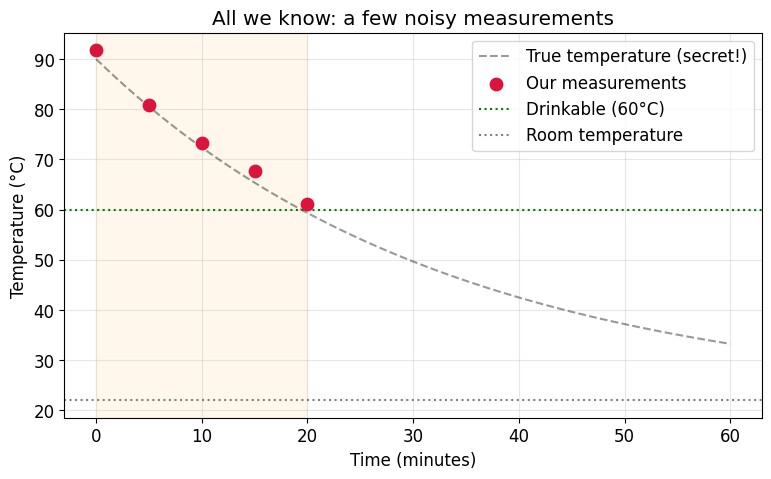

In [ ]:
T_ROOM = 22.0          # room temperature (°C)
T_START = 90.0         # coffee temperature when poured (°C)
K_TRUE = 0.03          # the mug's secret cooling rate (per minute) — the AI does NOT know this

N_POINTS = 5           #@param {type:"slider", min:3, max:15, step:1}
NOISE = 1            #@param {type:"slider", min:0.0, max:3.0, step:0.5}
MEASURE_UNTIL = 20   #@param {type:"slider", min:5, max:30, step:5}
T_END = 60.0           # we want predictions for the full hour

def true_temperature(t, k=K_TRUE):
    # The exact solution of Newton's law (only used to create data and to check answers)
    return T_ROOM + (T_START - T_ROOM) * np.exp(-k * t)

t_data_np = np.linspace(0, MEASURE_UNTIL, N_POINTS)
T_data_np = true_temperature(t_data_np) + NOISE * np.random.randn(N_POINTS)

t_full = np.linspace(0, T_END, 300)

plt.plot(t_full, true_temperature(t_full), "k--", alpha=0.4, label="True temperature (secret!)")
plt.scatter(t_data_np, T_data_np, s=80, c="crimson", zorder=5, label="Our measurements")
plt.axhline(60, color="green", ls=":", label="Drinkable (60°C)")
plt.axhline(T_ROOM, color="gray", ls=":", label="Room temperature")
plt.axvspan(0, MEASURE_UNTIL, color="orange", alpha=0.08)
plt.xlabel("Time (minutes)"); plt.ylabel("Temperature (°C)")
plt.title("All we know: a few noisy measurements"); plt.legend(); plt.show()

### A small but important note: scaling
Neural networks like numbers around 0–1, not "90 degrees" or "60 minutes". So we divide time by 60 and temperature by 100 before training, and convert back when we plot. (This is a standard step — it just makes training fast and stable.)

In [ ]:
T_SCALE, TIME_SCALE = 100.0, T_END

def to_tensor(x):
    return torch.tensor(x, dtype=torch.float32).view(-1, 1)

t_data = to_tensor(t_data_np / TIME_SCALE)
T_data = to_tensor(T_data_np / T_SCALE)
T_room_s = T_ROOM / T_SCALE
t_plot = to_tensor(t_full / TIME_SCALE)

def make_network():
    # A tiny network: 1 input (time) -> 1 output (temperature)
    return nn.Sequential(
        nn.Linear(1, 32), nn.Tanh(),
        nn.Linear(32, 32), nn.Tanh(),
        nn.Linear(32, 1),
    )

def predict(model):
    with torch.no_grad():
        return model(t_plot).numpy().ravel() * T_SCALE

def plot_prediction(pred, title, color):
    plt.plot(t_full, true_temperature(t_full), "k--", alpha=0.4, label="True temperature")
    plt.plot(t_full, pred, color=color, lw=3, label="AI prediction")
    plt.scatter(t_data_np, T_data_np, s=80, c="crimson", zorder=5, label="Measurements")
    plt.axhline(60, color="green", ls=":"); plt.axhline(T_ROOM, color="gray", ls=":")
    plt.axvspan(0, MEASURE_UNTIL, color="orange", alpha=0.08)
    plt.ylim(0, 110); plt.xlabel("Time (minutes)"); plt.ylabel("Temperature (°C)")
    plt.title(title); plt.legend(); plt.show()

def drinkable_time(pred):
    below = np.where(pred <= 60)[0]
    return t_full[below[0]] if len(below) else None

true_drink = np.log((T_START - T_ROOM) / (60 - T_ROOM)) / K_TRUE
print(f"(Secret answer: the coffee really reaches 60°C at {true_drink:.1f} minutes)")

(Secret answer: the coffee really reaches 60°C at 19.4 minutes)


## 3.  Attempt #1: a regular neural network

The network only gets one instruction: **"go through the measurement points."**

Trained in 3.2 s, final error: 2.17e-05


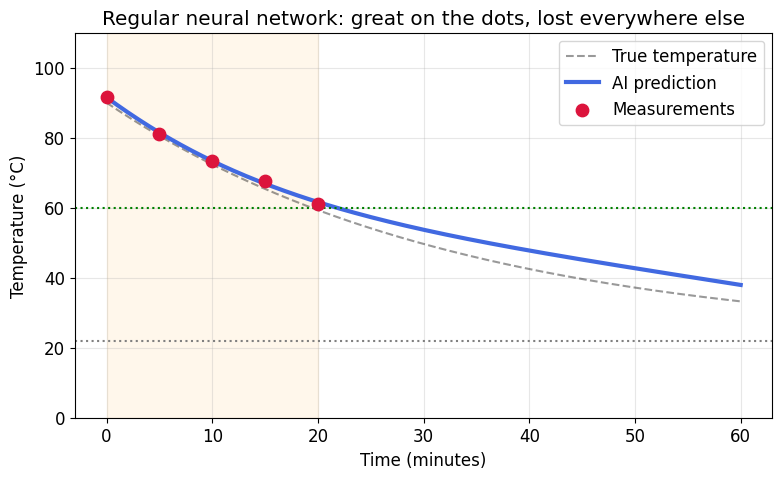

Regular NN says the coffee is drinkable at: 21.9 min
Regular NN says after 1 hour: 37.9°C   (truth: 33.2°C)


In [ ]:
start = time.time()
torch.manual_seed(1)
plain_nn = make_network()
optimizer = torch.optim.Adam(plain_nn.parameters(), lr=5e-3)

for step in range(3000):
    optimizer.zero_grad()
    loss = ((plain_nn(t_data) - T_data) ** 2).mean()   # only "fit the dots"
    loss.backward()
    optimizer.step()

print(f"Trained in {time.time() - start:.1f} s, final error: {loss.item():.2e}")
pred_plain = predict(plain_nn)
plot_prediction(pred_plain, "Regular neural network: great on the dots, lost everywhere else", "royalblue")
d = drinkable_time(pred_plain)
print(f"Regular NN says the coffee is drinkable at: {d:.1f} min" if d else "Regular NN says the coffee NEVER becomes drinkable 🤷")
print(f"Regular NN says after 1 hour: {pred_plain[-1]:.1f}°C   (truth: {true_temperature(T_END):.1f}°C)")

###  What went wrong?
It fits the measurements nicely... but outside the orange region it just makes something up.

Anybody knows things the network doesn't:
- coffee keeps cooling down,
- it slows down as it gets close to room temperature,
- it never gets colder than the room.

The network has **data**, but no **common sense about the world**. Let's give it some.

## 4.  Attempt #2: the Physics-Informed Neural Network

Same tiny network, but now its training "score" (the loss) has **two parts**:

| Part | What it says |
|---|---|
| **Data loss** | "Go through the measurement points" (same as before) |
| **Physics loss** | "At *every* moment in time, your curve must obey Newton's law of cooling" |

How do we check the physics? PyTorch can calculate the **slope** of the network's curve ($\frac{dT}{dt}$) automatically, using the same tool it uses for training (`autograd`). Then we just check:

$$\underbrace{\frac{dT}{dt} + k\,(T - T_{room})}_{\text{should be } 0} $$

We check this at 100 "physics points" spread across the whole hour — **we don't need measurements there**, the physics rule is enough!

In this first version, we pretend we **know** the mug's $k$.

In [ ]:
# Points in time where we check the physics (no measurements needed here!)
t_physics = torch.linspace(0, 1, 100).view(-1, 1).requires_grad_(True)

def physics_residual(model, kappa):
    T = model(t_physics)
    dTdt = torch.autograd.grad(T, t_physics, torch.ones_like(T), create_graph=True)[0]
    # Newton's law in our scaled units (kappa = k * 60 because time was divided by 60)
    return dTdt + kappa * (T - T_room_s)

def train_pinn(kappa, steps=3000, learn_k=False, t_d=t_data, T_d=T_data, seed=1):
    torch.manual_seed(seed)
    model = make_network()
    params = list(model.parameters())
    if learn_k:
        kappa = nn.Parameter(torch.tensor(float(kappa)))   # k becomes something the AI can tune!
        params.append(kappa)
    optimizer = torch.optim.Adam(params, lr=5e-3)
    k_history = []

    for step in range(steps):
        optimizer.zero_grad()
        data_loss = ((model(t_d) - T_d) ** 2).mean()                 # 1) fit the dots
        physics_loss = (physics_residual(model, kappa) ** 2).mean()   # 2) obey the physics
        loss = data_loss + 0.1 * physics_loss
        loss.backward()
        optimizer.step()
        if learn_k:
            k_history.append(kappa.item() / TIME_SCALE)
    return model, (kappa.item() / TIME_SCALE if learn_k else None), k_history

Trained in 4.7 s


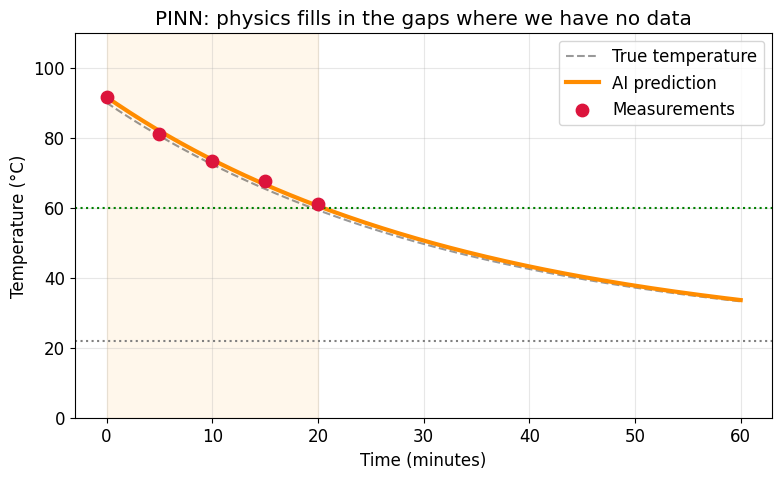

PINN says the coffee is drinkable at: 20.5 min   (truth: 19.4 min)
PINN says after 1 hour: 33.6°C   (truth: 33.2°C)


In [ ]:
start = time.time()
pinn, _, _ = train_pinn(kappa=K_TRUE * TIME_SCALE)
print(f"Trained in {time.time() - start:.1f} s")

pred_pinn = predict(pinn)
plot_prediction(pred_pinn, "PINN: physics fills in the gaps where we have no data", "darkorange")
print(f"PINN says the coffee is drinkable at: {drinkable_time(pred_pinn):.1f} min   (truth: {true_drink:.1f} min)")
print(f"PINN says after 1 hour: {pred_pinn[-1]:.1f}°C   (truth: {true_temperature(T_END):.1f}°C)")

### Side by side

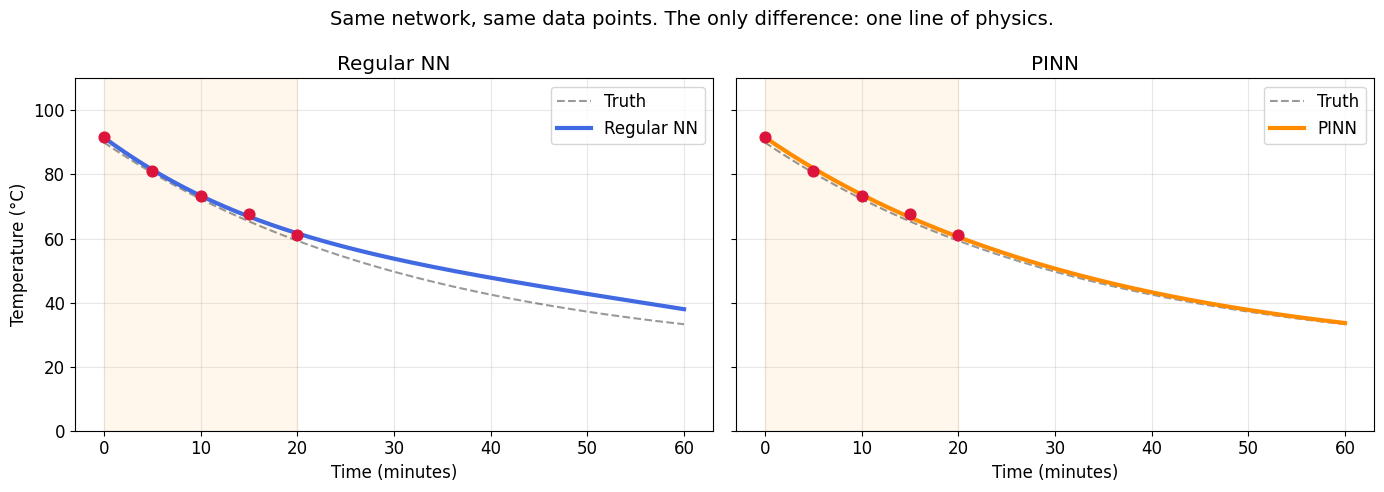

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, pred, name, c in [(axes[0], pred_plain, "Regular NN", "royalblue"), (axes[1], pred_pinn, "PINN", "darkorange")]:
    ax.plot(t_full, true_temperature(t_full), "k--", alpha=0.4, label="Truth")
    ax.plot(t_full, pred, color=c, lw=3, label=name)
    ax.scatter(t_data_np, T_data_np, s=60, c="crimson", zorder=5)
    ax.axvspan(0, MEASURE_UNTIL, color="orange", alpha=0.08)
    ax.set_ylim(0, 110); ax.set_xlabel("Time (minutes)"); ax.set_title(name); ax.legend()
axes[0].set_ylabel("Temperature (°C)")
plt.suptitle("Same network, same data points. The only difference: one line of physics.", fontsize=14)
plt.tight_layout(); plt.show()

## 5. The superpower: discovering what we don't know

So far we cheated: we told the PINN the mug's cooling rate $k$. In real science, that's often **exactly the thing we want to find out**.

So let's make $k$ a **learnable number**. We start with a bad guess and let the AI adjust it during training, together with the network.

The AI only knows:
- the 5 noisy measurements,
- that coffee cools according to *some* Newton's law.

Trained in 7.4 s
Starting guess:  k = 0.0100
AI discovered:   k = 0.0286
True value:      k = 0.0300   (error: 4.8%)


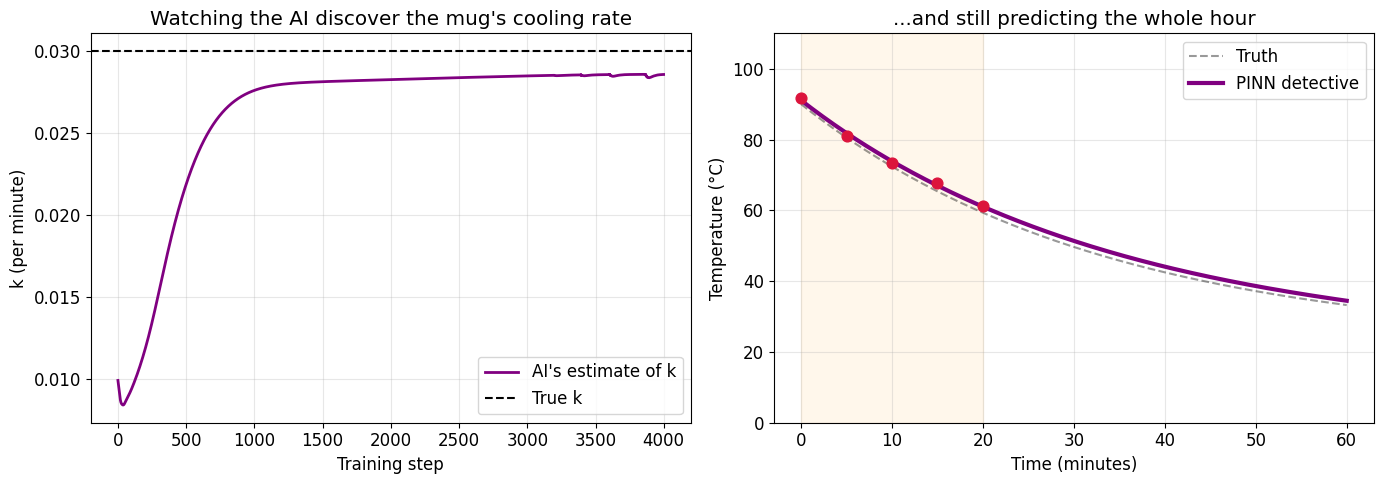

In [ ]:
K_GUESS = 0.01   # deliberately wrong starting guess

start = time.time()
pinn_detective, k_found, k_history = train_pinn(kappa=K_GUESS * TIME_SCALE, steps=4000, learn_k=True)
print(f"Trained in {time.time() - start:.1f} s")
print(f"Starting guess:  k = {K_GUESS:.4f}")
print(f"AI discovered:   k = {k_found:.4f}")
print(f"True value:      k = {K_TRUE:.4f}   (error: {abs(k_found - K_TRUE) / K_TRUE * 100:.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(k_history, color="purple", lw=2, label="AI's estimate of k")
axes[0].axhline(K_TRUE, color="k", ls="--", label="True k")
axes[0].set_xlabel("Training step"); axes[0].set_ylabel("k (per minute)")
axes[0].set_title("Watching the AI discover the mug's cooling rate"); axes[0].legend()

pred_det = predict(pinn_detective)
axes[1].plot(t_full, true_temperature(t_full), "k--", alpha=0.4, label="Truth")
axes[1].plot(t_full, pred_det, color="purple", lw=3, label="PINN detective")
axes[1].scatter(t_data_np, T_data_np, s=60, c="crimson", zorder=5)
axes[1].axvspan(0, MEASURE_UNTIL, color="orange", alpha=0.08)
axes[1].set_ylim(0, 110); axes[1].set_xlabel("Time (minutes)"); axes[1].set_ylabel("Temperature (°C)")
axes[1].set_title("...and still predicting the whole hour"); axes[1].legend()
plt.tight_layout(); plt.show()

 **Why isn't it exactly 0.030?** Our thermometer is noisy and we only have 5 points, so a perfect answer isn't possible — but the AI gets remarkably close from very little information. Try increasing `N_POINTS` or lowering `NOISE` in Section 2 and watch the estimate improve.

###  Fun experiment: paper cup vs. ceramic mug vs. thermos

Three mystery containers. We give the AI 5 noisy measurements from each — **without telling it which is which** — and let it measure each one's $k$.

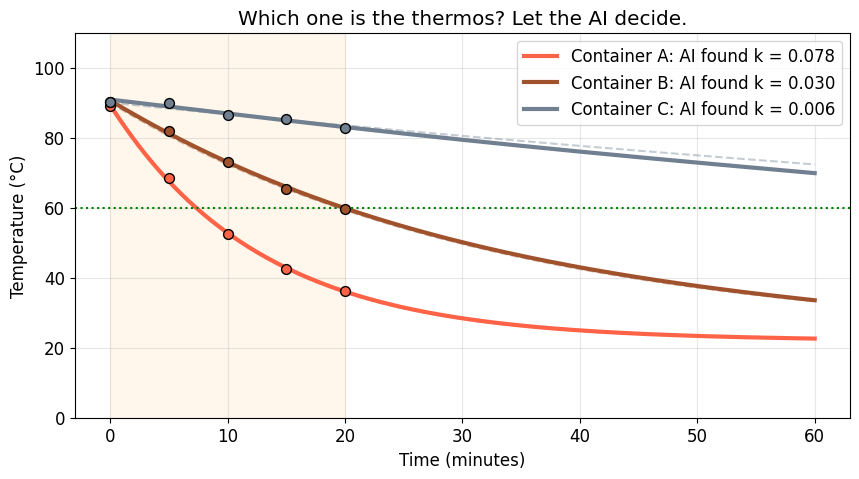

Trained 3 PINNs in 20.5 s

Container A: AI says k = 0.0782 | truth k = 0.0800 -> it was the paper cup 
Container B: AI says k = 0.0297 | truth k = 0.0300 -> it was the ceramic mug 
Container C: AI says k = 0.0061 | truth k = 0.0050 -> it was the thermos 


In [ ]:
mystery = {"Container A": 0.08, "Container B": 0.03, "Container C": 0.005}  # paper cup, mug, thermos
colors = ["tomato", "sienna", "slategray"]

start = time.time()
plt.figure(figsize=(10, 5))
results = {}
for (name, k_secret), c in zip(mystery.items(), colors):
    T_meas = true_temperature(t_data_np, k_secret) + NOISE * np.random.randn(N_POINTS)
    model, k_est, _ = train_pinn(kappa=K_GUESS * TIME_SCALE, steps=4000, learn_k=True,
                                 T_d=to_tensor(T_meas / T_SCALE))
    results[name] = (k_secret, k_est)
    plt.plot(t_full, predict(model), color=c, lw=3, label=f"{name}: AI found k = {k_est:.3f}")
    plt.plot(t_full, true_temperature(t_full, k_secret), "--", color=c, alpha=0.4)
    plt.scatter(t_data_np, T_meas, color=c, s=50, edgecolor="k", zorder=5)

plt.axvspan(0, MEASURE_UNTIL, color="orange", alpha=0.08)
plt.axhline(60, color="green", ls=":")
plt.ylim(0, 110); plt.xlabel("Time (minutes)"); plt.ylabel("Temperature (°C)")
plt.title("Which one is the thermos? Let the AI decide."); plt.legend(); plt.show()

print(f"Trained 3 PINNs in {time.time() - start:.1f} s\n")
labels = {0.08: "paper cup ", 0.03: "ceramic mug ", 0.005: "thermos "}
for name, (k_secret, k_est) in results.items():
    print(f"{name}: AI says k = {k_est:.4f} | truth k = {k_secret:.4f} -> it was the {labels[k_secret]}")

## 6.  Why scientists care

What we just did with a coffee cup is the same idea used in serious research:

- **Medicine:** estimating blood flow and pressure in arteries from a few blurry MRI frames
- **Climate & weather:** filling gaps between sparse weather stations while respecting the laws of fluid flow
- **Engineering:** predicting how heat spreads in a battery or how a bridge bends, from a handful of sensors
- **Earth science:** finding underground properties (like how easily water flows through rock) that can't be measured directly

The pattern is always the same:

>  **Data is expensive and scarce** +  **we know the rules of the game** → PINNs shine.

### Key takeaways
1. A regular neural network only knows the data you give it — it can't reason beyond it.
2. A PINN adds the laws of physics to the training score, so it behaves sensibly **even where there is no data**.
3. A PINN can work backwards and **discover unknown physical properties** from a few measurements.

###  Try it yourself
Go back to Section 2 and change the sliders:
- Use only **3** points. Does the PINN still work? Does the regular NN?
- Crank the **noise** up to 3°C. Who handles it better?
- Measure for **30 minutes** instead of 10. Does the regular NN improve?

### Further reading
- Raissi, Perdikaris & Karniadakis (2019), *Physics-informed neural networks* — the original paper
- Ben Moseley's blog post *"So, what is a physics-informed neural network?"* — a friendly next step